In [91]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tc5061_proyecto_equipo5.config import FIGURES_DIR, RAW_DATA_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
AZUL, NARANJA, ROJO = "#2a78d6","#FF8000", "#e34948"

def leer_csv(ruta, **kwargs):
    """Intenta UTF-8 y, si falla, latin-1 (los archivos viejos usan esa codificación)."""
    try:
        return pd.read_csv(ruta, encoding="utf-8", **kwargs), "utf-8"
    except UnicodeDecodeError:
        return pd.read_csv(ruta, encoding="latin-1", **kwargs), "latin-1"

# Inventario de archivos

In [92]:
todos = sorted(RAW_DATA_DIR.rglob("*.csv"))
nomenclatura = [p for p in todos if "nomenclatura" in p.name.lower()]
archivos = [p for p in todos if p not in nomenclatura]

print(f"Archivos de viajes: {len(archivos)} ({sum(p.stat().st_size for p in archivos) / 1e9:.2f} GB)")
print(f"Primero: {archivos[0].name} | último: {archivos[-1].name}")
print(f"Nomenclatura: {[p.name for p in nomenclatura]}")

Archivos de viajes: 142 (3.11 GB)
Primero: datos_abiertos_2014_12.csv | último: datos_abiertos_2026_09.csv
Nomenclatura: ['nomenclatura_2026_09.csv']


Parte A - Nomeclatura de estaciones

In [93]:
#Que tiene el archivo de nomeclatura
estaciones, enc = leer_csv(nomenclatura[-1])
print(f"Codificación: {enc} | estaciones: {len(estaciones)} | columnas: {list(estaciones.columns)}")
print(estaciones.dtypes)
estaciones.sample(10, random_state=42)

Codificación: utf-8 | estaciones: 484 | columnas: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64
dtype: object


,id,name,latitude,longitude,dpcapacity
418,442,(GDL-303) Sta. Irene / Av. Lopez Mateos Sur,20.67,-103.39,19
474,510,(ZPN-102) C. Volcán del Colli/V. del Ajusco,20.64,-103.43,15
181,190,(GDL-123) C. Aurelio L. Gallardo / Av. México,20.68,-103.38,11
446,473,(GDL-351) Valentín Gómez Farías / Irineo Paz,20.66,-103.32,11
297,313,(ZPN-057) C. Escultores / Av. Guadalupe,20.66,-103.42,15
148,157,(GDL-090) Calz. Federalismo / C. Durango,20.70,-103.36,23
380,397,(GDL-279) Belen / Av. de los Maestros,20.69,-103.35,19
386,409,(GDL-286) T. V. Gómez /Av. José Maria Morelos,20.68,-103.38,19
479,515,(GDL-295) C. Tarahumaras / Av. Manuel Acuña,20.68,-103.39,15
227,236,(GDL-169) Blvrd. García Barragán/ C. Rio Zapo,20.65,-103.32,23


In [94]:
#Faltan datos o hay repetidos? 
print("Nulos por columna:")
print(estaciones.isna().sum())
print()
print("ids repetidos:", estaciones["id"].duplicated().sum())
print("nombres repetidos:", estaciones["name"].duplicated().sum())
print("coordenadas repetidas:", estaciones[["latitude", "longitude"]].duplicated().sum())


Nulos por columna:
id            0
name          0
latitude      0
longitude     0
dpcapacity    0
dtype: int64

ids repetidos: 0
nombres repetidos: 0
coordenadas repetidas: 2


In [95]:
#Los ids con consecutivos o tienen saltos
ids = estaciones["id"]
print("id minimo:", ids.min(), "| id maximo:", ids.max())
print("ids que faltan dentro del rango:", ids.max() - ids.min() + 1 - ids.nunique())

id minimo: 2 | id maximo: 519
ids que faltan dentro del rango: 34


In [96]:
estaciones["name"].head(15).tolist()

['(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.',
 '(GDL-002) C. Colonias  / Av.  Niños héroes',
 '(GDL-003) C. Vidrio / Av. Chapultepec',
 '(GDL-004) C. Ghilardi /C. Miraflores',
 '(GDL-005) C. San Diego /Calzada Independencia',
 '(GDL-006) C. Venustiano Carranza /C. Reforma',
 '(GDL-007) C. Epigmenio Glez./Av. Cristobal C.',
 '(GDL-008) C. Ignacio Zaragoza / C. J. Angulo',
 '(GDL-009) Calz. Federalismo/ C. J. Angulo',
 '(GDL-010) C. Cruz verde / C. Joaquin Angulo',
 '(GDL-011) C. Garibaldi / C. Frías',
 '(GDL-012) C. Joaquín Angulo / C. Ghilardi',
 '(GDL-013) C. Vidrio  / C. Marsella',
 '(GDL-014) C. J. Angulo/C José Clemente Orozco',
 '(GDL-015) C. Herrera y Cairo /C. Pedro Buzeta']

In [97]:
# Extrae el texto antes del primer guion dentro de un parentesis: (GDL-001) => GDL"
estaciones["prefijo"] = estaciones["name"].str.extract(r"\(\s*([A-Za-z]+)\s*-", expand=False)
print(f"Nombres con prefijo: {estaciones['prefijo'].notna().mean():.0%}")
estaciones["prefijo"].value_counts(dropna=False)

Nombres con prefijo: 100%


prefijo
GDL    356
ZPN    110
TLQ     17
NaN      1
Name: count, dtype: int64

In [98]:
#Capacidad (numero de anclajes)
print(estaciones["dpcapacity"].value_counts().sort_index())

dpcapacity
0       4
11     54
15    201
19    175
23     39
27      2
30      1
31      7
39      1
Name: count, dtype: int64


In [99]:
# Estaciones con capacidad 0
estaciones[estaciones["dpcapacity"] == 0]

,id,name,latitude,longitude,dpcapacity,prefijo
94,99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,20.69,-103.33,0,ZPN
104,109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,20.72,-103.39,0,ZPN
111,116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,20.69,-103.33,0,ZPN
129,138,ex-(ZPN-044),20.70,-103.36,0,ZPN


In [100]:
# Las de mayor capacidad
estaciones.sort_values("dpcapacity", ascending=False).head(10)


,id,name,latitude,longitude,dpcapacity,prefijo
48,51,(GDL-049) Lopez Cotilla / Penitenciaría,20.67,-103.36,39,GDL
270,281,(GDL-208) Av. España / Av. Federalismo,20.66,-103.36,31,GDL
252,263,(GDL-190) C. Anahuac / Av. Revolución,20.67,-103.34,31,GDL
277,288,(ZPN-048) Av. J. Parres Arias / Prol. López C,20.73,-103.39,31,ZPN
280,291,(ZPN-051) Av. Periférico G. Morín / Av. J. Pa,20.74,-103.38,31,ZPN
282,293,(ZPN-053) Prol. Laureles / Av. Periférico G.,20.74,-103.38,31,ZPN
272,283,(GDL-210) Av. Washington / Calz. Independenci,20.66,-103.35,31,GDL
260,271,(GDL-198) Av. Alcalde / C. Hospital,20.69,-103.35,31,GDL
254,265,(GDL-192) Calle A1 / Av. Manuel A. Camacho,20.71,-103.37,30,GDL
62,65,(GDL-063) C. Colonias / C. López Cotilla,20.67,-103.37,27,GDL


In [101]:
if estaciones["prefijo"].notna().any():
    display(estaciones.groupby("prefijo")["dpcapacity"].agg(["count", "sum", "mean", "min", "max"]))

,count,sum,mean,min,max
prefijo,,,,,
GDL,356,6119,17.19,11,39
TLQ,17,259,15.24,15,19
ZPN,110,1778,16.16,0,31


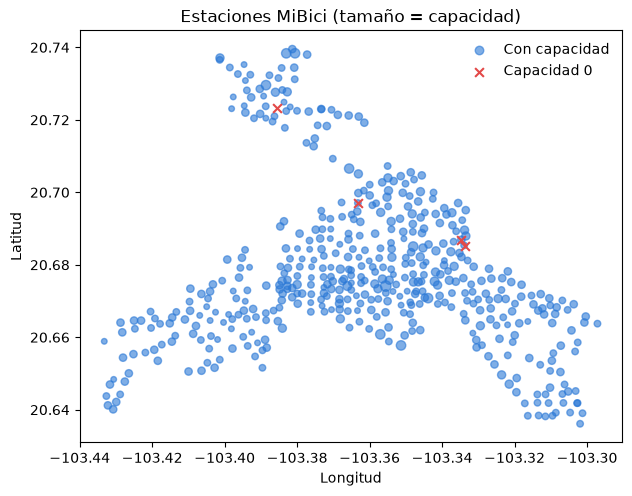

In [102]:
#Ubicacion
fig, ax = plt.subplots(figsize=(7, 7))
cero = estaciones["dpcapacity"] == 0
ax.scatter(estaciones.loc[~cero, "longitude"], estaciones.loc[~cero, "latitude"],
           s=estaciones.loc[~cero, "dpcapacity"] * 1.5, alpha=0.6, color=AZUL, label="Con capacidad")
ax.scatter(estaciones.loc[cero, "longitude"], estaciones.loc[cero, "latitude"],
           s=40, color=ROJO, marker="x", label="Capacidad 0")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Estaciones MiBici (tamaño = capacidad)")
ax.set_aspect("equal")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_estaciones.png", bbox_inches="tight")
plt.show()

In [103]:
# uv add folium
import folium

ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
ATRIBUCION = "Mapa base: Esri, HERE, Garmin, © OpenStreetMap contributors"

mapa = folium.Map(location=[estaciones["latitude"].mean(), estaciones["longitude"].mean()],
                  zoom_start=12, tiles=ESRI, attr=ATRIBUCION)
for _, e in estaciones.iterrows():
    sin_cap = e["dpcapacity"] == 0
    folium.CircleMarker(
        location=[e["latitude"], e["longitude"]],
        radius=3 if sin_cap else e["dpcapacity"] / 3,
        color=ROJO if sin_cap else AZUL, fill=True, fill_opacity=0.7, weight=1,
        popup=f"{e['id']} - {e['name']}<br>Capacidad: {e['dpcapacity']}",
        tooltip=e["name"],
    ).add_to(mapa)
mapa.save(FIGURES_DIR / "eda_estaciones_mapa.html")
mapa

### Conclusiones de la nomenclatura
- Estaciones: 484
- Datos faltantes / repetidos: 0 faltantes, 2 coordenadas repetidas
- Ids: minimo 2 | maximo 519 , faltan 34 en el rango
- Nombres y zonas: Guadalajara 356, zapopan 110, tlaquepaque 17, NA 1
- Capacidad:  1 estacion con capacidad de 39 anclajes,7 estaciones con 31 anclajes ... estaciones con capacidad 0: 4

# Parte B - Viajes de un rango de meses

In [104]:
# B1 => Elegir rango y cargar
def mes_del_archivo(ruta):
    """'datos_abiertos_2025_03.csv' -> '2025-03'."""
    """ regex: ano que empiece con 20 seguido de _ o -m y de uno a dos digitos para el mes """
    m = re.search(r"(20\d{2})[_\-](\d{1,2})", ruta.stem)
    return f"{m.group(1)}-{int(m.group(2)):02d}" if m else None


def normalizar(nombre):
    """'Inicio del viaje' / 'Inicio_del_viaje' -> 'inicio_del_viaje' (sin acentos)."""
    """ Limpia los nombres de columna para que sean iguales todos los anos"""
    nombre = unicodedata.normalize("NFKD", str(nombre)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", nombre.lower()).strip("_")


meses_disponibles = sorted(m for p in archivos if (m := mes_del_archivo(p)))
print(f"Meses disponibles: {meses_disponibles[0]} a {meses_disponibles[-1]}")

#  Por defecto: los ultimos 6 meses disponibles 
INICIO, FIN = meses_disponibles[-6], meses_disponibles[-1]
seleccion = [p for p in archivos if (m := mes_del_archivo(p)) and INICIO <= m <= FIN]
print(f"Rango: {INICIO} a {FIN} ({len(seleccion)} archivos)")

Meses disponibles: 2014-12 a 2026-09
Rango: 2026-04 a 2026-09 (6 archivos)


In [105]:
PERSONALES = ("usuario", "genero", "nacimiento")   # columnas que se eliminan al cargar

#lista donde se iran guardando los meses y dicc para anotar que columnas trae cada mes
partes, columnas_por_mes = [], {}

for ruta in seleccion:
    d, enc = leer_csv(ruta, dtype=str)
    d.columns = [normalizar(c) for c in d.columns]
    d = d[[c for c in d.columns if not any(p in c for p in PERSONALES)]]
    columnas_por_mes[mes_del_archivo(ruta)] = list(d.columns)
    d["mes_archivo"] = mes_del_archivo(ruta)
    partes.append(d)
    print(f"{ruta.name}: {len(d):,} viajes | {enc}")

viajes = pd.concat(partes, ignore_index=True)
del partes
print(f"\nTotal: {len(viajes):,} viajes | memoria: {viajes.memory_usage(deep=True).sum() / 1e6:.0f} MB")

# Todos los meses traen las mismas columnas?
distintas = {m: c for m, c in columnas_por_mes.items() if c != list(columnas_por_mes.values())[0]}
print("Columnas:", list(columnas_por_mes.values())[0])
print("Meses con columnas distintas:", distintas or "ninguno")
viajes.head()

datos_abiertos_2026_04.csv: 351,851 viajes | utf-8
datos_abiertos_2026_05.csv: 315,895 viajes | utf-8
datos_abiertos_2026_06.csv: 355,303 viajes | utf-8
datos_abiertos_2026_07.csv: 388,257 viajes | utf-8
datos_abiertos_2026_08.csv: 393,524 viajes | utf-8
datos_abiertos_2026_09.csv: 490,056 viajes | utf-8

Total: 2,294,886 viajes | memoria: 244 MB
Columnas: ['viaje_id', 'inicio_del_viaje', 'fin_del_viaje', 'origen_id', 'destino_id']
Meses con columnas distintas: ninguno


,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,mes_archivo
0,43570783,2026-04-01 00:00:26,2026-04-01 00:18:17,358,158,2026-04
1,43570784,2026-04-01 00:00:44,2026-04-01 00:00:47,200,200,2026-04
2,43570786,2026-04-01 00:01:11,2026-04-01 00:03:46,287,95,2026-04
3,43570787,2026-04-01 00:01:14,2026-04-01 00:07:13,200,63,2026-04
4,43570791,2026-04-01 00:02:03,2026-04-01 00:12:24,193,155,2026-04


In [106]:
#B2 => Nulos y duplicados
print(viajes.isna().sum())
print()
print("filas duplicadas:", viajes.duplicated().sum())
col_id = next((c for c in viajes.columns if "viaje" in c and "id" in c), None)
if col_id:
    print(f"ids de viaje repetidos ({col_id}):", viajes[col_id].duplicated().sum())

viaje_id            0
inicio_del_viaje    0
fin_del_viaje       0
origen_id           0
destino_id          0
mes_archivo         0
dtype: int64

filas duplicadas: 758
ids de viaje repetidos (viaje_id): 758


In [ ]:
#Se identifica cada columna por palabra clave y se revisa que las fechas caigan en el mes de su archivo. Si muchas quedan fuera, pandas esta confundiendo dia y mes
def columna(palabra):
    return next(c for c in viajes.columns if palabra in c)

COL_INICIO, COL_FIN = columna("inicio"), columna("fin")

COL_ORIGEN, COL_DESTINO = columna("origen"), columna("destino")
print("Ejemplos de fecha tal como vienen:", viajes[COL_INICIO].head(3).tolist())

viajes["inicio"] = pd.to_datetime(viajes[COL_INICIO], errors="coerce")
viajes["fin"] = pd.to_datetime(viajes[COL_FIN], errors="coerce")
viajes["origen"] = pd.to_numeric(viajes[COL_ORIGEN], errors="coerce").astype("Int32")
viajes["destino"] = pd.to_numeric(viajes[COL_DESTINO], errors="coerce").astype("Int32")
viajes["duracion_min"] = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60

fuera = viajes["inicio"].dt.strftime("%Y-%m") != viajes["mes_archivo"]
print(f"Fechas de inicio inválidas: {viajes['inicio'].isna().sum():,}")
print(f"Viajes fuera del mes de su archivo: {fuera.mean():.2%}")
viajes["duracion_min"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

Ejemplos de fecha tal como vienen: ['2026-04-01 00:00:26', '2026-04-01 00:00:44', '2026-04-01 00:01:11']
Fechas de inicio inválidas: 0
Viajes fuera del mes de su archivo: 0.00%


count   2,294,886.00
mean           10.77
std            10.59
min             0.00
1%              0.15
5%              1.65
25%             5.45
50%             9.10
75%            14.35
95%            24.53
99%            34.08
max         4,543.02
Name: duracion_min, dtype: float64

Duracion negativa o cero: 0.03%
Menos de 1 minuto:        3.95%
Mas de 30 min:           1.75%


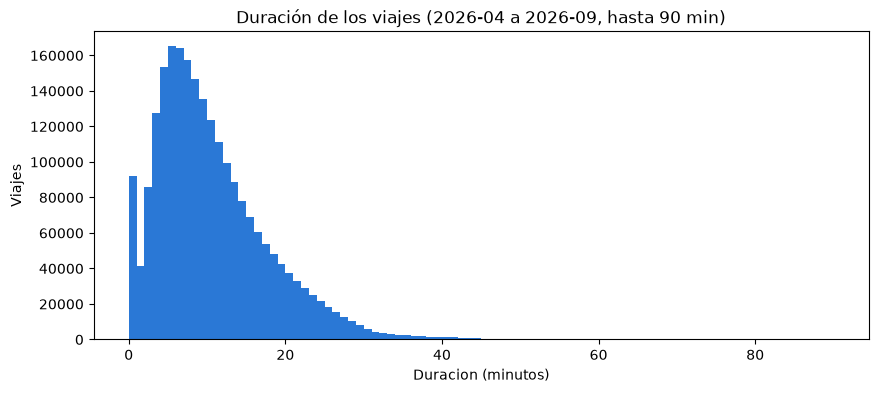

In [108]:
d = viajes["duracion_min"]
print(f"Duracion negativa o cero: {(d <= 0).mean():.2%}")
print(f"Menos de 1 minuto:        {((d > 0) & (d < 1)).mean():.2%}")
print(f"Mas de 30 min:           {(d > 30).mean():.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d[(d > 0) & (d <= 90)], bins=90, color=AZUL)
ax.set_xlabel("Duracion (minutos)")
ax.set_ylabel("Viajes")
ax.set_title(f"Duración de los viajes ({INICIO} a {FIN}, hasta 90 min)")
fig.savefig(FIGURES_DIR / "eda_duracion.png", bbox_inches="tight")
plt.show()

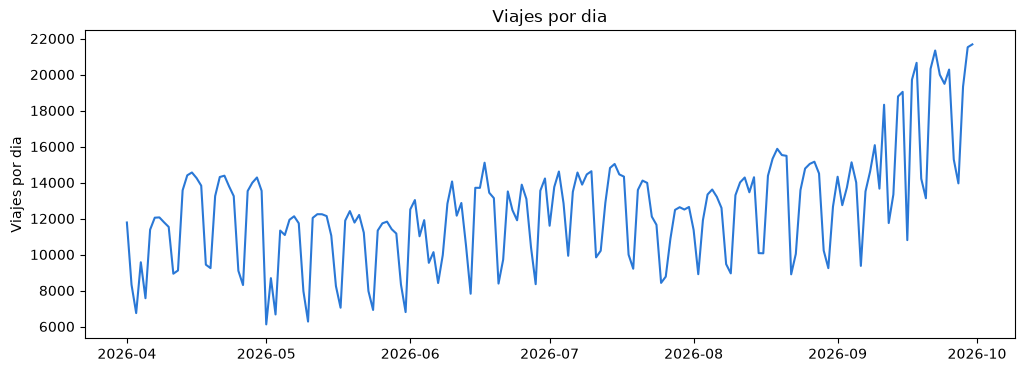

Promedio: 12,540 viajes/día | mínimo: 6,118 (2026-05-01) | maximo: 21,677 (2026-09-30)


In [109]:
#Cuando ocurren los viajes
por_dia = viajes.groupby(viajes["inicio"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(por_dia.index), por_dia.values, color=AZUL)
ax.set_ylabel("Viajes por dia")
ax.set_title("Viajes por dia")
fig.savefig(FIGURES_DIR / "eda_viajes_por_dia.png", bbox_inches="tight")
plt.show()
print(f"Promedio: {por_dia.mean():,.0f} viajes/día | mínimo: {por_dia.min():,} ({por_dia.idxmin()}) | maximo: {por_dia.max():,} ({por_dia.idxmax()})")

In [110]:
dias_es = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

tabla_dias = por_dia.rename("viajes").to_frame()
tabla_dias.index = pd.to_datetime(tabla_dias.index)
tabla_dias["dia_semana"] = [dias_es[d] for d in tabla_dias.index.dayofweek]
tabla_dias["fin_de_semana"] = tabla_dias.index.dayofweek >= 5

# Lo "normal" de cada día de la semana: la mediana del mismo día de la semana en ese mes
mes = tabla_dias.index.to_period("M")
tabla_dias["normal"] = tabla_dias.groupby([mes, "dia_semana"])["viajes"].transform("median")
tabla_dias["vs_normal_%"] = (100 * (tabla_dias["viajes"] / tabla_dias["normal"] - 1)).round(1)

# Los 15 días con menos viajes
# tabla_dias.sort_values("viajes").head(50)

tabla_dias[~tabla_dias["fin_de_semana"]].sort_values("vs_normal_%").head(10)
# 02-03 de abril => Jueves y viernes santo
# 01 de mayo Dia del trabajo
# 16 de septiembre => Independencia




,viajes,dia_semana,fin_de_semana,normal,vs_normal_%
inicio,,,,,
2026-04-03,6746,Viernes,False,"12,390.50",-45.60
2026-05-01,6118,Viernes,False,"11,165.00",-45.20
2026-04-02,8321,Jueves,False,"13,542.00",-38.60
2026-09-16,10800,Miércoles,False,"16,077.00",-32.80
2026-09-07,13508,Lunes,False,"19,056.00",-29.10
2026-06-05,9538,Viernes,False,"12,976.00",-26.50
2026-06-08,9971,Lunes,False,"13,505.00",-26.20
2026-09-01,14322,Martes,False,"19,040.00",-24.80
2026-09-08,14621,Martes,False,"19,040.00",-23.20


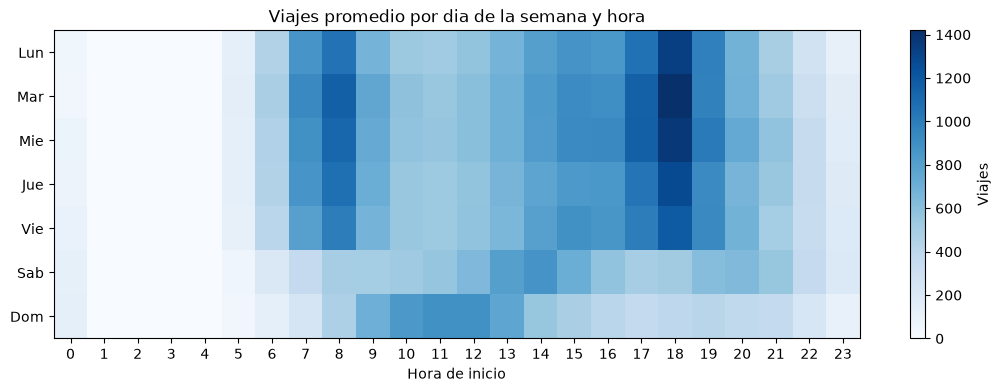

In [111]:
# Dia de la semana × hora: muestra horas pico y diferencia entre laborales y fin de semana
dias = ["Lun", "Mar", "Mie", "Jue", "Vie", "Sab", "Dom"]
tabla = (viajes.groupby([viajes["inicio"].dt.dayofweek, viajes["inicio"].dt.hour]).size()
         .unstack(fill_value=0))
n_semanas = viajes["inicio"].dt.to_period("W").nunique()
tabla = tabla / n_semanas   # viajes promedio por semana en cada celda

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(tabla.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), dias)
ax.set_xticks(range(24), range(24))
ax.set_xlabel("Hora de inicio")
ax.grid(False)
ax.set_title("Viajes promedio por dia de la semana y hora")
fig.colorbar(im, ax=ax, label="Viajes")
fig.savefig(FIGURES_DIR / "eda_dia_hora.png", bbox_inches="tight")
plt.show()

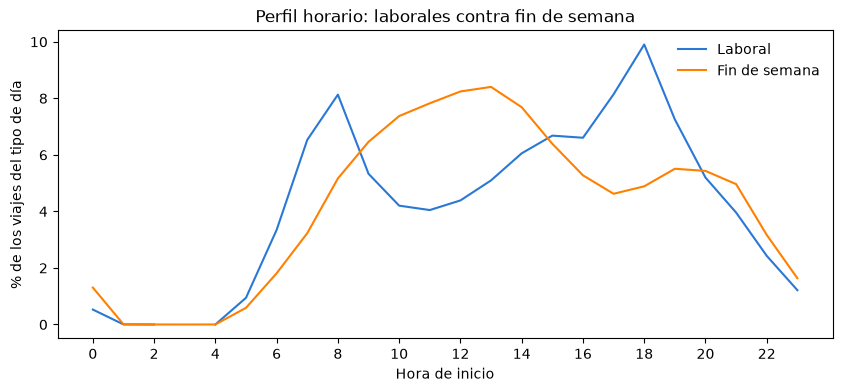

In [112]:
tipo = np.where(viajes["inicio"].dt.dayofweek >= 5, "Fin de semana", "Laboral")
perfil = viajes.groupby([tipo, viajes["inicio"].dt.hour]).size().unstack(0)
perfil = perfil / perfil.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(perfil.index, perfil["Laboral"], color=AZUL, label="Laboral")
ax.plot(perfil.index, perfil["Fin de semana"], color=NARANJA, label="Fin de semana")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora de inicio")
ax.set_ylabel("% de los viajes del tipo de día")
ax.set_title("Perfil horario: laborales contra fin de semana")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_perfil_horario.png", bbox_inches="tight")
plt.show()

In [113]:
#Desde que estaciones
salidas = viajes["origen"].value_counts().rename("salidas")
llegadas = viajes["destino"].value_counts().rename("llegadas")
uso = pd.concat([salidas, llegadas], axis=1).fillna(0).astype(int)
uso["flujo_neto"] = uso["llegadas"] - uso["salidas"]   # >0 recibe más de lo que envía
uso = uso.join(estaciones.set_index("id")[["name", "dpcapacity", "latitude", "longitude"]])

print(f"Estaciones con viajes en el rango: {len(uso)}")
print(f"Estaciones con viajes que NO estan en la nomenclatura: {uso['name'].isna().sum()}")
print(f"Estaciones de la nomenclatura SIN viajes en el rango: {(~estaciones['id'].isin(uso.index)).sum()}")
uso.sort_values("salidas", ascending=False).head(10)

Estaciones con viajes en el rango: 471
Estaciones con viajes que NO estan en la nomenclatura: 2
Estaciones de la nomenclatura SIN viajes en el rango: 15


,salidas,llegadas,flujo_neto,name,dpcapacity,latitude,longitude
51,56206,62355,6149,(GDL-049) Lopez Cotilla / Penitenciaría,39.00,20.67,-103.36
271,34979,30436,-4543,(GDL-198) Av. Alcalde / C. Hospital,31.00,20.69,-103.35
11,31522,28392,-3130,(GDL-009) Calz. Federalismo/ C. J. Angulo,23.00,20.68,-103.35
35,30505,34530,4025,(GDL-033) Av. Hidalgo / C. Pedro Loza,15.00,20.68,-103.35
50,25222,25981,759,(GDL-048) C. Constancio Hernández/ Av. Juaréz,23.00,20.67,-103.36
194,25211,12635,-12576,(GDL-127) Av. Vallarta / Av. de Los Arcos,19.00,20.67,-103.38
54,23641,24977,1336,(GDL-052) Av. Juarez /16 de Septiembre,23.00,20.68,-103.35
38,21071,21082,11,(GDL-036) C. Marcos Castellanos/ C. Morelos,23.00,20.68,-103.36
52,20951,19984,-967,(GDL-050) C.Pedro Moreno /Federalismo,23.00,20.68,-103.35
75,18406,18209,-197,(GDL-073) Av. La Paz / Av. Federalismo,19.00,20.67,-103.36


El 10% de las estaciones concentra el 34% de las salidas


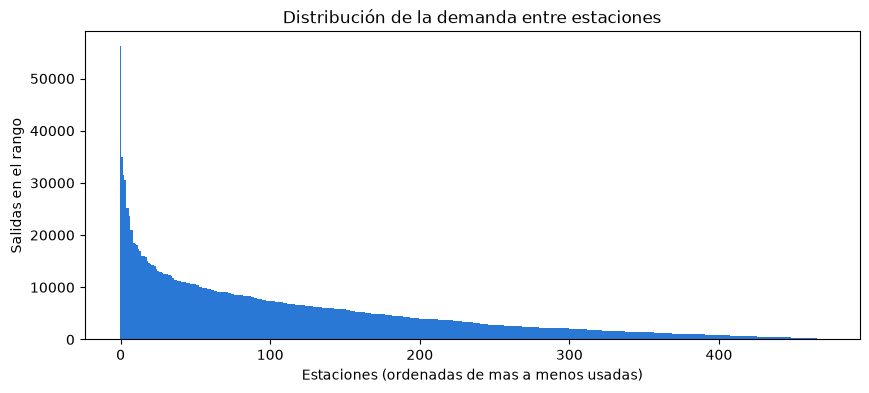

In [114]:
# Concentracion: ¿que % de los viajes sale del 10% de estaciones mas usadas?
orden = uso["salidas"].sort_values(ascending=False)
top10 = orden.head(int(len(orden) * 0.1)).sum() / orden.sum()
print(f"El 10% de las estaciones concentra el {top10:.0%} de las salidas")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(orden)), orden.values, color=AZUL, width=1.0)
ax.set_xlabel("Estaciones (ordenadas de mas a menos usadas)")
ax.set_ylabel("Salidas en el rango")
ax.set_title("Distribución de la demanda entre estaciones")
fig.savefig(FIGURES_DIR / "eda_demanda_estaciones.png", bbox_inches="tight")
plt.show()

In [115]:
# Estaciones que mas envian y mas reciben (relevante para P2: rebalanceo)
print("Mas emisoras (salen mas bicis de las que llegan):")
display(uso.sort_values("flujo_neto").head(5)[["name", "salidas", "llegadas", "flujo_neto", "dpcapacity"]])
print("Mas receptoras (llegan mas bicis de las que salen):")
display(uso.sort_values("flujo_neto", ascending=False).head(5)[["name", "salidas", "llegadas", "flujo_neto", "dpcapacity"]])

Mas emisoras (salen mas bicis de las que llegan):


,name,salidas,llegadas,flujo_neto,dpcapacity
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,25211,12635,-12576,19.00
271,(GDL-198) Av. Alcalde / C. Hospital,34979,30436,-4543,31.00
288,(ZPN-048) Av. J. Parres Arias / Prol. López C,10424,6737,-3687,31.00
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,31522,28392,-3130,23.00
197,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta,9592,7398,-2194,15.00


Mas receptoras (llegan mas bicis de las que salen):


,name,salidas,llegadas,flujo_neto,dpcapacity
51,(GDL-049) Lopez Cotilla / Penitenciaría,56206,62355,6149,39.00
341,(ZPN-070)Av. Avila Camacho / Av. Patria,6490,10817,4327,19.00
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,30505,34530,4025,15.00
56,(GDL-054) Av. Juárez / Calz. Independencia,14360,18001,3641,27.00
384,(GDL-252) C. Calpulalpan / C. Independencia,6648,10146,3498,23.00


In [120]:
# Mapa: tamaño = salidas; color = emisora (naranja) o receptora (azul)
m2 = folium.Map(location=[estaciones["latitude"].mean(), estaciones["longitude"].mean()],
                zoom_start=12, tiles=ESRI, attr=ATRIBUCION)
con_coord = uso.dropna(subset=["latitude"])
escala = 15 / np.sqrt(con_coord["salidas"].max())
for est_id, e in con_coord.iterrows():
    folium.CircleMarker(
        location=[e["latitude"], e["longitude"]],
        radius=max(2, np.sqrt(e["salidas"]) * escala),
        color=NARANJA if e["flujo_neto"] < 0 else AZUL, fill=True, fill_opacity=0.6, weight=1,
        popup=f"{est_id} - {e['name']}<br>Salidas: {e['salidas']:,}<br>Llegadas: {e['llegadas']:,}",
        tooltip=e["name"],
    ).add_to(m2)
m2.save(FIGURES_DIR / "eda_uso_estaciones_mapa.html")



### Conclusiones de la nomenclatura
* Estaciones: 484
* Datos faltantes / repetidos: 0 faltantes, 2 coordenadas repetidas
* Ids: minimo 2 | maximo 519 , faltan 34 en el rango
* Nombres y zonas: Guadalajara 356, zapopan 110, tlaquepaque 17, NA 1
* Capacidad:  1 estacion con capacidad de 39 anclajes,7 estaciones con 31 anclajes ... estaciones con capacidad 0: 4
### Conclusiones de los viajes
* Rango: abril a septiembre de 2026 (6 meses), 2,294,886 viajes y 471 estaciones con viajes. Ocupan 244 MB en memoria.
* Calidad: sin nulos, mismas columnas en todos los meses y 0% de fechas fuera de su mes. Hay 758 viajes duplicados por viaje_id.
* Duración: mediana de 9.1 min y p95 de 24.5 min. El 3.95% dura menos de 1 min, 0.03% tiene duración menor o igual a 0 y 1.75% más de 30 min.
* Demanda diaria: promedio de 12,540 viajes por día con un ciclo semanal marcado. Mínimo el 1 de mayo (6,118, festivo) y máximo el 30 de septiembre (21,677) tendencia a la alsa?? TODO.
* Septiembre: la demanda sube de unos 13 mil a unos 20 mil viajes por día. Causa: TODO .
* Horarios: entre semana hay dos picos, 8 h y 18 h (el mayor a las 18 h). El fin de semana tiene un pico al mediodía y el domingo se concentra en la mañana. Entre la 1 y las 4 h casi no hay viajes.
* Estaciones: el 10% de las estaciones concentra el 34% de las salidas. La más usada es GDL-049 López Cotilla / Penitenciaría (56,206 salidas, capacidad 39).
* Flujo neto: la más emisora es GDL-127 Av. Vallarta / Av. de Los Arcos (-12,576 en 6 meses, unas 70 bicis por día con 19 anclajes). La más receptora es GDL-049 (+6,149).
* Cruce con la nomenclatura: 15 estaciones del catálogo no tuvieron viajes y 2 estaciones con viajes no están en el catálogo.
* Limpieza: Sugerencia: eliminar duplicados por viaje_id, viajes de menos de 1 min con mismo origen y destino, y duraciones menores o iguales a 0 o mayores de 3 h. Excluir de P2 las estaciones con capacidad 0 o fuera del catálogo.
* Agregar: P1 necesita hora, día de la semana, fin de semana y festivos como variables, 
